Three RL algorithms have been used which is adapted from the unit practicals. These include Q-learning, SARSA, and Dynamic Q-learning.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from gymnasium import spaces

from IPython.display import display

There is 24 hourly decisions. This is from 7:00 to 7:00 next day. Every one of the methods start with 50% home battery SOC and 40% EV arrival SOC. This is a single day scheduling experiment. The battery energy is not carried between days or assigned a terminal price. We have also used $\gamma$ = 1 to minimize the undiscounted daily costing.

The table below shows the features.

| Indices | Information |
|---|---|
| 0-1 | Hour as sine/cosine |
| 2-4 | Battery SOC, EV SOC, EV plugged in |
| 5-9 | Solar now/next hour, base load now, tariff now/next hour |
| 10-12 | Sunny/cloudy/rainy one-hot |
| 13-14 | Washer/dishwasher pending flags |
| 15-16 | Washer/dishwasher hours remaining |

**Action:** battery $b\in\{0,1,2\}$ means charge or idle or discharge, EV $e\in\{0,1\}$ means waitor charge, and appliance $j\in\{0,1\}$ means defer or start the next eligible pending appliance. The combined action is

$$a=4b+2e+j,\qquad a\in\{0,\ldots,11\}.$$

**Battery transition:** internal energy is $E=C\cdot SOC$, $C=10$ kWh,
rate $P=5$ and efficiency $\eta=0.95$. For the one-hour step, a charge command
draws $c=\min(P,(C-E)/\eta)$ from the AC supply and sets $E'=E+\eta c$.
A discharge command removes $q=\min(P,E)$ internally, delivers $d=\eta q$
to the house/grid and sets $E'=E-q$. Idle changes neither. Rate limits apply to AC charging and internal discharge.

**Grid balance and reward:**

$$g=L+L^{appliance}+L^{EV}+c-PV-d,$$
$$cost=p\max(g,0)-0.03\max(-g,0),$$
$$r=-(cost+penalty).$$

The EV charges only while plugged in. It is up to its physical 100% capacity. It should reach 80% by 07:00. Also, each missing kWh costs a $1 penalty at termination. Each
appliance must run once for two hours before its completion deadline. A missed job costs $2 once. Unavailable commands also have no effect and battery limits are
enforced directly. We have recorded the electricity bill and penalties separately. So, leaving tasks unfinished cannot be mistaken for successful cost reduction.

**Stochasticity:** weather is sampled with probabilities 0.6/0.3/0.1. Solar/load have independent hourly noise and it is bounded to the stated observation ranges. Given
weather, clock, current/one-hour forecast values, SOCs and job progress, the observed transitions have a fixed conditional distribution.

In [2]:
HOURS = np.arange(24)
WEATHERS = ("sunny", "cloudy", "rainy")
BASE_LOAD = np.array([.4,.3,.3,.3,.3,.4,.8,1.2,1.,.6,.5,.5,
                      .6,.5,.5,.6,.9,1.5,2.,1.8,1.4,1.,.7,.5])
PRICE = np.full(24, .25)
PRICE[9:15], PRICE[15:21] = .10, .55
BATTERY_CAPACITY, BATTERY_RATE, EFFICIENCY = 10., 5., .95
EV_CAPACITY, EV_RATE, EV_TARGET = 60., 7., .8
FEED_IN, EV_PENALTY, JOB_PENALTY = .03, 1., 2.
APPLIANCES = (("washer", 1., 2, 7, 22), ("dishwasher", 1.2, 2, 8, 23))

def sample_day(rng, weather=None):
    weather = weather or str(rng.choice(WEATHERS, p=[.6, .3, .1]))
    scale = {"sunny": 1., "cloudy": .5, "rainy": .2}[weather]
    curve = np.maximum(0., np.sin(np.pi*(HOURS-6)/12))
    curve[(HOURS < 6) | (HOURS > 18)] = 0.
    solar = np.clip(5*scale*curve*(1+rng.normal(0,.1,24)), 0., 7.5)
    load = np.clip(BASE_LOAD*(1+rng.normal(0,.1,24)), .1, 5.)
    return {"weather": weather, "solar": solar, "load": load}

def decode_action(action):
    return action//4, (action//2)%2, action%2

In [3]:
class EnergyEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, weather=None):
        super().__init__()
        if weather not in (None, *WEATHERS):
            raise ValueError("weather must be sunny, cloudy or rainy")
        self.weather = weather
        self.action_space = spaces.Discrete(12)
        low = np.array([-1,-1]+[0]*15, dtype=np.float32)
        high = np.array([1,1,1,1,1,7.5,7.5,5,.55,.55,1,1,1,1,1,2,2], dtype=np.float32)
        self.observation_space = spaces.Box(low, high, dtype=np.float32)
        self.t = 24

    @property
    def hour(self):
        return (7+self.t)%24

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.day = sample_day(self.np_random, self.weather)
        self.t, self.battery_soc, self.ev_soc = 0, .5, .4
        self.pending = [True, True]
        self.hours_left = [0, 0]
        self.missed = 0
        return self._obs(), {}

    def step(self, action):
        if self.t >= 24:
            raise RuntimeError("Call reset() before starting another day")
        if not self.action_space.contains(action):
            raise ValueError("Action must be an integer from 0 to 11")
        h = self.hour
        battery, ev, appliance = decode_action(int(action))
        solar, load = self.day["solar"][h], self.day["load"][h]
        penalty = appliance_kwh = ev_kwh = 0.

        # Start the next eligible pending appliance, then advance running jobs.
        if appliance:
            for j, (_, _, duration, earliest, deadline) in enumerate(APPLIANCES):
                if self.pending[j] and earliest <= h <= deadline-duration:
                    self.pending[j], self.hours_left[j] = False, duration
                    break
        for j, (_, power, _, _, _) in enumerate(APPLIANCES):
            if self.hours_left[j] > 0:
                appliance_kwh += power
                self.hours_left[j] -= 1

        # EV is away from 07:00 to 18:00. Its arrival SOC is already 40%.
        if ev and (h >= 18 or h < 7):
            ev_kwh = min(EV_RATE, (1-self.ev_soc)*EV_CAPACITY)
            self.ev_soc = min(1., self.ev_soc+ev_kwh/EV_CAPACITY)

        # Same battery equations as the original notebook; dt = one hour.
        battery_before = self.battery_soc*BATTERY_CAPACITY
        batt_in = batt_out = 0.
        if battery == 0:
            batt_in = min(BATTERY_RATE, (1-self.battery_soc)*BATTERY_CAPACITY/EFFICIENCY)
            self.battery_soc += batt_in*EFFICIENCY/BATTERY_CAPACITY
        elif battery == 2:
            drawn = min(BATTERY_RATE, self.battery_soc*BATTERY_CAPACITY)
            self.battery_soc -= drawn/BATTERY_CAPACITY
            batt_out = drawn*EFFICIENCY
        self.battery_soc = min(1., max(0., self.battery_soc))

        net = load+appliance_kwh+ev_kwh+batt_in-solar-batt_out
        grid_import, grid_export = max(net, 0.), max(-net, 0.)
        cost = grid_import*PRICE[h]-grid_export*FEED_IN
        for j, (_, _, duration, _, deadline) in enumerate(APPLIANCES):
            if self.pending[j] and h >= deadline-duration:
                self.pending[j] = False
                self.missed += 1
                penalty += JOB_PENALTY
        self.t += 1
        terminated = self.t == 24
        shortfall = max(EV_TARGET-self.ev_soc, 0.)*EV_CAPACITY if terminated else 0.
        penalty += EV_PENALTY*shortfall
        info = {"hour":h, "cost":cost, "penalty":penalty,
                "grid_import":grid_import, "grid_export":grid_export,
                "solar":solar, "load":load, "appliance_kwh":appliance_kwh,
                "ev_kwh":ev_kwh, "battery_in":batt_in, "battery_out":batt_out,
                "battery_before":battery_before,
                "battery_after":self.battery_soc*BATTERY_CAPACITY,
                "ev_soc":self.ev_soc, "ev_shortfall":shortfall,
                "missed_jobs":self.missed, "weather":self.day["weather"]}
        return self._obs(), float(-(cost+penalty)), terminated, False, info

    def _obs(self):
        h, nxt = self.hour, (self.hour+1)%24
        terminal = self.t >= 24
        profiles = ([0.]*5 if terminal else
                    [self.day["solar"][h],self.day["solar"][nxt],self.day["load"][h],PRICE[h],PRICE[nxt]])
        return np.array([np.sin(2*np.pi*h/24),np.cos(2*np.pi*h/24),
                         self.battery_soc,self.ev_soc,float(not terminal and (h >= 18 or h < 7)),
                         *profiles,*[float(self.day["weather"] == w) for w in WEATHERS],
                         *[float(p) for p in self.pending],*self.hours_left], dtype=np.float32)

In [4]:
from gymnasium.utils.env_checker import check_env
check_env(EnergyEnv(), skip_render_check=True)
env = EnergyEnv()
obs, _ = env.reset(seed=0)
check_rng = np.random.default_rng(0)
for step in range(24):
    obs, reward, done, truncated, info = env.step(int(check_rng.integers(12)))
    assert env.observation_space.contains(obs)
    assert 0 <= env.battery_soc <= 1
    supply = info["solar"]+info["battery_out"]+info["grid_import"]
    demand = info["load"]+info["appliance_kwh"]+info["ev_kwh"]+info["battery_in"]+info["grid_export"]
    assert np.isclose(supply,demand)
    assert np.isclose(reward,-info["cost"]-info["penalty"])
    assert done == (step == 23) and not truncated
print("Environment contract, energy balance, battery bounds and reward checks passed.")

Environment contract, energy balance, battery bounds and reward checks passed.


In [5]:
NUM_ACTIONS = 12
NUM_STATES = 24*5*4*3*3*3+1
TERMINAL = NUM_STATES-1

def discretise(obs):
    hour = int(round(np.arctan2(obs[0],obs[1])*24/(2*np.pi)))%24
    battery = min(int(obs[2]*5),4)
    ev = int(np.searchsorted([.5,.65,.8-1e-7],float(obs[3]),side="right"))
    weather = int(np.argmax(obs[10:13]))
    # Each job: 0 pending, 1 running, 2 finished or already penalised.
    washer = 0 if obs[13] else (1 if obs[15] > 0 else 2)
    dishwasher = 0 if obs[14] else (1 if obs[16] > 0 else 2)
    return int(((((hour*5+battery)*4+ev)*3+weather)*3+washer)*3+dishwasher)

def epsilon_greedy(Q, state, epsilon, rng):
    if rng.random() < epsilon:
        return int(rng.integers(NUM_ACTIONS))
    best = np.flatnonzero(Q[state] == Q[state].max())
    return int(rng.choice(best))

def epsilon_at(episode, episodes, decay=True):
    # Finite epsilon decay with a floor; this is not a GLIE guarantee.
    return max(.05, 1.-.95*episode/max(1.,.8*(episodes-1))) if decay else .1

# Q-learning from Practical 5

```text
Q1 Initialise Q=0 and the terminal row=0.
Q2 For each episode, reset and discretise the first observation.
Q3 Choose an epsilon-greedy action.
Q4 Step and discretise the next observation (or use the terminal state).
Q5 Set y=r if terminal, otherwise y=r+gamma*max_a Q(s',a).
Q6 Update Q(s,a) <- Q(s,a)+alpha*(y-Q(s,a)).
Q7 Move to s' and repeat; return the greedy policy after training.
```

In [6]:
def Qlearning(env, gamma=1., alpha=.3, max_episodes=15000, seed=0, decay=True):
    Q = np.zeros((NUM_STATES,NUM_ACTIONS))  # [Q1]
    returns = np.zeros(max_episodes)
    rng = np.random.default_rng(seed)
    for episode in range(max_episodes):  # [Q2]
        epsilon = epsilon_at(episode,max_episodes,decay)
        obs, _ = env.reset(seed=seed*100_000+episode)
        state = discretise(obs)
        while True:
            action = epsilon_greedy(Q,state,epsilon,rng)  # [Q3]
            obs, reward, terminated, truncated, _ = env.step(action)  # [Q4]
            next_state = TERMINAL if terminated else discretise(obs)
            target = reward if terminated else reward+gamma*Q[next_state].max()  # [Q5]
            Q[state,action] += alpha*(target-Q[state,action])  # [Q6]
            returns[episode] += reward
            state = next_state  # [Q7]
            if terminated or truncated:
                break
    return Q, np.argmax(Q,axis=1), returns

# SARSA from Practical
```text
S1 Initialise Q=0 and the terminal row=0.
S2 Reset/discretise and choose the first epsilon-greedy action.
S3 Step and observe r and s'.
S4 Choose the next epsilon-greedy action a' if not terminal.
S5 Set y=r if terminal, otherwise y=r+gamma*Q(s',a').
S6 Update Q(s,a) <- Q(s,a)+alpha*(y-Q(s,a)).
S7 Move to s', reuse a', and repeat; return the greedy policy.
```

In [7]:
def SARSA(env, gamma=1., alpha=.3, max_episodes=15000, seed=0, decay=True):
    Q = np.zeros((NUM_STATES,NUM_ACTIONS))  # [S1]
    returns = np.zeros(max_episodes)
    rng = np.random.default_rng(seed)
    for episode in range(max_episodes):
        epsilon = epsilon_at(episode,max_episodes,decay)
        obs, _ = env.reset(seed=seed*100_000+episode)
        state = discretise(obs)
        action = epsilon_greedy(Q,state,epsilon,rng)  # [S2]
        while True:
            obs, reward, terminated, truncated, _ = env.step(action)  # [S3]
            next_state = TERMINAL if terminated else discretise(obs)
            next_action = 0 if terminated else epsilon_greedy(Q,next_state,epsilon,rng)  # [S4]
            target = reward if terminated else reward+gamma*Q[next_state,next_action]  # [S5]
            Q[state,action] += alpha*(target-Q[state,action])  # [S6]
            returns[episode] += reward
            state, action = next_state, next_action  # [S7] Reuse the chosen action.
            if terminated or truncated:
                break
    return Q, np.argmax(Q,axis=1), returns

# Dynamic Q learning from Practical 6
```text
D1 Initialise Q=0, the terminal row=0 and an empty model.
D2 Reset/discretise; choose an epsilon-greedy action.
D3 Take a real environment step and observe r,s'.
D4 Apply the Q-learning update to the real transition.
D5 Update the model's count, mean reward and successor counts.
D6 Repeat n times: sample a visited (s,a), reward estimate and successor.
D7 Apply a Q-learning update to that simulated transition.
D8 Move to the real next state and repeat; return the greedy policy.
```

In [8]:
class TableLookup:
    """Practical 6 stochastic model, storing only observed state-action entries."""
    def __init__(self):
        self.entries, self.pairs = {}, []

    def learn(self, state, action, reward, next_state):
        key = (state,action)
        if key not in self.entries:
            self.entries[key] = {"count":0, "reward":0., "next":{}}
            self.pairs.append(key)
        entry = self.entries[key]
        entry["count"] += 1
        entry["reward"] += (reward-entry["reward"])/entry["count"]
        counts = entry["next"]
        counts[next_state] = counts.get(next_state,0)+1

    def simulate(self, rng):
        state, action = self.pairs[int(rng.integers(len(self.pairs)))]
        entry = self.entries[state,action]
        successors = list(entry["next"])
        probabilities = np.array(list(entry["next"].values()),dtype=float)/entry["count"]
        next_state = successors[int(rng.choice(len(successors),p=probabilities))]
        return state, action, entry["reward"], next_state


def DynaQ(env, gamma=1., alpha=.3, max_episodes=15000, seed=0, planning_steps=5):
    Q = np.zeros((NUM_STATES,NUM_ACTIONS))  # [D1]
    returns = np.zeros(max_episodes)
    model = TableLookup()
    rng = np.random.default_rng(seed)
    planning_rng = np.random.default_rng(seed+10_000)
    for episode in range(max_episodes):
        epsilon = epsilon_at(episode,max_episodes)
        obs, _ = env.reset(seed=seed*100_000+episode)
        state = discretise(obs)
        while True:
            action = epsilon_greedy(Q,state,epsilon,rng)  # [D2]
            obs, reward, terminated, truncated, _ = env.step(action)  # [D3]
            next_state = TERMINAL if terminated else discretise(obs)
            target = reward if terminated else reward+gamma*Q[next_state].max()
            Q[state,action] += alpha*(target-Q[state,action])  # [D4] Direct learning.
            model.learn(state,action,reward,next_state)  # [D5] Learn the model.
            for _ in range(planning_steps):
                s, a, r, next_s = model.simulate(planning_rng)  # [D6]
                y = r if next_s == TERMINAL else r+gamma*Q[next_s].max()
                Q[s,a] += alpha*(y-Q[s,a])  # [D7] Planning update.
            returns[episode] += reward
            state = next_state  # [D8] Keep real state separate from planning states.
            if terminated or truncated:
                break
    return Q, np.argmax(Q,axis=1), returns

In [9]:
q_direct, _, r_direct = Qlearning(EnergyEnv(),max_episodes=5,seed=99)
q_dyna, _, r_dyna = DynaQ(EnergyEnv(),max_episodes=5,seed=99,planning_steps=0)
assert np.array_equal(q_direct,q_dyna) and np.array_equal(r_direct,r_dyna)
assert np.all(q_dyna[TERMINAL] == 0)
print("Dyna-Q with zero planning exactly matches Q-learning; terminal values stay zero.")

Dyna-Q with zero planning exactly matches Q-learning; terminal values stay zero.


# Baseline and Evaluation

In [10]:
def rule_policy(obs):
    solar, load, price, plugged = obs[5],obs[7],obs[8],obs[4]
    battery = 0 if solar > load else (2 if price >= .55-1e-6 else 1)
    ev = int(plugged and price < .55-1e-6 and obs[3] < EV_TARGET-1e-6)
    appliance = int(price <= .10+1e-6)
    return battery*4+ev*2+appliance


def evaluate(policy, days=300, seed_offset=20_000_000):
    """Each policy receives the same unseen days; pi arrays are evaluated greedily."""
    env, rows = EnergyEnv(), []
    for day in range(days):
        obs, _ = env.reset(seed=seed_offset+day)
        rng = np.random.default_rng(seed_offset+day)
        total_return = bill = penalties = 0.
        while True:
            if isinstance(policy,str) and policy == "random":
                action = int(rng.integers(NUM_ACTIONS))
            else:
                action = int(policy(obs)) if callable(policy) else int(policy[discretise(obs)])
            obs, reward, terminated, truncated, info = env.step(action)
            total_return += reward
            bill += info["cost"]
            penalties += info["penalty"]
            if terminated or truncated:
                break
        rows.append({"day":day, "weather":info["weather"], "return":total_return,
                     "bill":bill, "penalty":penalties, "total_cost":bill+penalties,
                     "ev_shortfall":info["ev_shortfall"], "missed_jobs":info["missed_jobs"],
                     "success":info["ev_shortfall"] < 1e-6 and info["missed_jobs"] == 0})
    return pd.DataFrame(rows)

# Hyperparameter tuning

In [11]:
TUNING_EPISODES = 3000
EPISODES = 15000
TUNING_SEEDS = [10,11]
SEEDS = [0,1,2]
VALIDATION_DAYS, TEST_DAYS = 100, 300
VALIDATION_OFFSET, TEST_OFFSET = 10_000_000, 20_000_000
TRAINERS = {"Q-learning":Qlearning, "SARSA":SARSA, "Dyna-Q":DynaQ}
tuning_rows = []
selected = {}
for name, trainer in TRAINERS.items():
    parameter = "planning_steps" if name == "Dyna-Q" else "alpha"
    values = [0,5,10] if name == "Dyna-Q" else [.1,.3,.5]
    for value in values:
        for seed in TUNING_SEEDS:
            _, pi, _ = trainer(EnergyEnv(),max_episodes=TUNING_EPISODES,seed=seed,**{parameter:value})
            result = evaluate(pi,days=VALIDATION_DAYS,seed_offset=VALIDATION_OFFSET)
            tuning_rows.append({"Agent":name,"Parameter":parameter,"Value":value,"Seed":seed,
                                "Validation cost":result.total_cost.mean(),
                                "Success (%)":100*result.success.mean()})
        print(name,parameter,value,"finished",flush=True)
    current = pd.DataFrame(tuning_rows)
    means = current[current.Agent == name].groupby("Value")["Validation cost"].mean()
    eligible = means[means.index > 0] if name == "Dyna-Q" else means
    best = eligible.idxmin()
    selected[name] = {parameter:int(best) if parameter == "planning_steps" else float(best)}
tuning = pd.DataFrame(tuning_rows)
display(tuning.groupby(["Agent","Parameter","Value"])["Validation cost"].agg(["mean","std"]))
print("Selected using validation only:",selected)

Q-learning alpha 0.1 finished
Q-learning alpha 0.3 finished
Q-learning alpha 0.5 finished
SARSA alpha 0.1 finished
SARSA alpha 0.3 finished
SARSA alpha 0.5 finished
Dyna-Q planning_steps 0 finished
Dyna-Q planning_steps 5 finished
Dyna-Q planning_steps 10 finished


mean       std
Agent      Parameter      Value                     
Dyna-Q     planning_steps 0.0    21.418717  2.564707
                          5.0    15.052445  0.364214
                          10.0   13.505671  2.557623
Q-learning alpha          0.1    17.785982  6.882337
                          0.3    21.418717  2.564707
                          0.5    14.633579  0.840322
SARSA      alpha          0.1    16.470972  2.351132
                          0.3    23.245775  6.488049
                          0.5    22.941339  2.447204

Selected using validation only: {'Q-learning': {'alpha': 0.5}, 'SARSA': {'alpha': 0.1}, 'Dyna-Q': {'planning_steps': 10}}


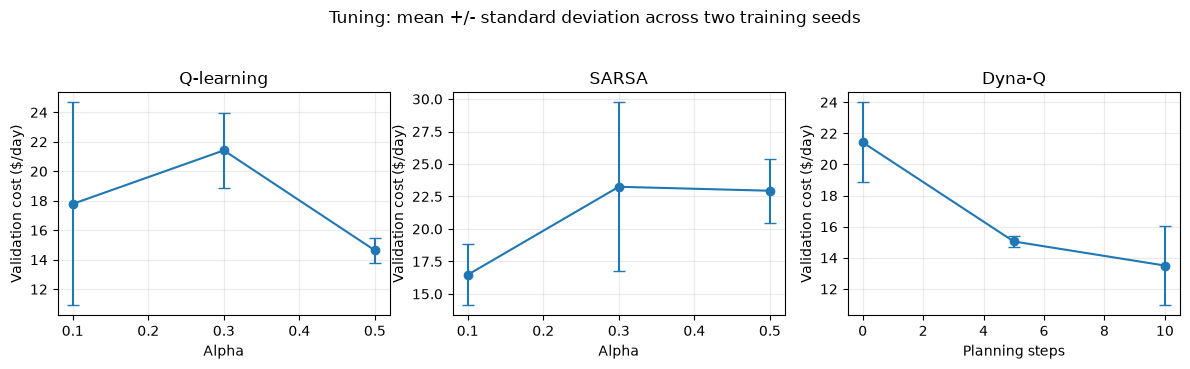

In [12]:
fig, axes = plt.subplots(1,3,figsize=(12,3.5))
for ax, name in zip(axes,TRAINERS):
    result = tuning[tuning.Agent == name].groupby("Value")["Validation cost"].agg(["mean","std"])
    ax.errorbar(result.index,result["mean"],yerr=result["std"],fmt="o-",capsize=4)
    ax.set(title=name,xlabel="Planning steps" if name == "Dyna-Q" else "Alpha",ylabel="Validation cost ($/day)")
    ax.grid(alpha=.25)
fig.suptitle("Tuning: mean +/- standard deviation across two training seeds",y=1.04)
plt.tight_layout()
plt.show()

### Check the change from fixed epsilon to decaying epsilon

In [13]:
best_alpha = selected["Q-learning"]["alpha"]
decay_rows = tuning[(tuning.Agent == "Q-learning") & (tuning.Value == best_alpha)].copy()
epsilon_rows = [{"Schedule":"Decay 1 to 0.05","Seed":row.Seed,
                 "Validation cost":row["Validation cost"]} for _,row in decay_rows.iterrows()]
for seed in TUNING_SEEDS:
    _, pi, _ = Qlearning(EnergyEnv(),alpha=best_alpha,max_episodes=TUNING_EPISODES,seed=seed,decay=False)
    result = evaluate(pi,days=VALIDATION_DAYS,seed_offset=VALIDATION_OFFSET)
    epsilon_rows.append({"Schedule":"Fixed 0.1","Seed":seed,"Validation cost":result.total_cost.mean()})
display(pd.DataFrame(epsilon_rows).groupby("Schedule")["Validation cost"].agg(["mean","std"]))

,mean,std
Schedule,,
Decay 1 to 0.05,14.633579,0.840322
Fixed 0.1,12.656898,0.297575


# Main training: three independent runs per agent

In [14]:
histories, policies, timings, test_frames = {}, {}, [], []
for name, trainer in TRAINERS.items():
    histories[name], policies[name] = [], []
    for seed in SEEDS:
        started = time.perf_counter()
        Q, pi, returns = trainer(EnergyEnv(),max_episodes=EPISODES,seed=seed,**selected[name])
        seconds = time.perf_counter()-started
        assert np.all(Q[TERMINAL] == 0) and np.isfinite(Q).all()
        histories[name].append(returns)
        policies[name].append(pi)
        timings.append({"Agent":name,"Seed":seed,"Seconds":seconds,"Real steps":24*EPISODES,
                        "Planning updates":24*EPISODES*selected[name].get("planning_steps",0)})
        result = evaluate(pi,days=TEST_DAYS,seed_offset=TEST_OFFSET)
        result["Agent"], result["Seed"] = name,seed
        test_frames.append(result)
        print(name,"seed",seed,"finished in",round(seconds,1),"seconds",flush=True)
for name, policy in [("Rule-based",rule_policy),("Random","random")]:
    result = evaluate(policy,days=TEST_DAYS,seed_offset=TEST_OFFSET)
    result["Agent"], result["Seed"] = name,-1
    test_frames.append(result)
test_results = pd.concat(test_frames,ignore_index=True)
display(pd.DataFrame(timings).round(2))

Q-learning seed 0 finished in 16.5 seconds
Q-learning seed 1 finished in 16.5 seconds
Q-learning seed 2 finished in 16.6 seconds
SARSA seed 0 finished in 16.1 seconds
SARSA seed 1 finished in 15.5 seconds
SARSA seed 2 finished in 16.6 seconds
Dyna-Q seed 0 finished in 100.3 seconds
Dyna-Q seed 1 finished in 100.4 seconds
Dyna-Q seed 2 finished in 100.3 seconds


,Agent,Seed,Seconds,Real steps,Planning updates
0,Q-learning,0,16.50,360000,0
1,Q-learning,1,16.45,360000,0
2,Q-learning,2,16.56,360000,0
3,SARSA,0,16.06,360000,0
4,SARSA,1,15.49,360000,0
5,SARSA,2,16.63,360000,0
6,Dyna-Q,0,100.33,360000,3600000
7,Dyna-Q,1,100.43,360000,3600000
8,Dyna-Q,2,100.30,360000,3600000


# Learning curves

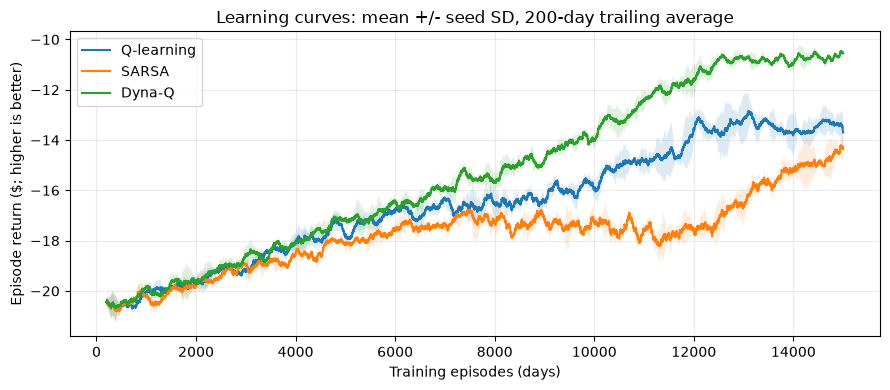

In [15]:
plt.figure(figsize=(9,4))
window = 200
for name, runs in histories.items():
    smoothed = np.array([np.convolve(run,np.ones(window)/window,mode="valid") for run in runs])
    mean, std = smoothed.mean(axis=0),smoothed.std(axis=0,ddof=1)
    x = np.arange(window,EPISODES+1)
    plt.plot(x,mean,label=name)
    plt.fill_between(x,mean-std,mean+std,alpha=.15)
plt.xlabel("Training episodes (days)")
plt.ylabel("Episode return ($; higher is better)")
plt.title("Learning curves: mean +/- seed SD, 200-day trailing average")
plt.legend()
plt.grid(alpha=.25)
plt.tight_layout()
plt.show()

# Unseen day results

Report electricity bill, penalties, total cost, task success and variation
between the three trained policies. Lower total cost is better. Seed SD is
the standard deviation of per-seed mean costs, not the spread of individual
test days. Baselines have one fixed policy, so their seed SD is shown as zero.
Three seeds provide a small descriptive comparison, not a significance test.

,Mean total cost ($),Seed SD ($),Mean bill ($),Mean penalties ($),Success (%),EV shortfall (kWh),Missed jobs
Agent,,,,,,,
Random,20.525,0.000,20.321,0.203,94.667,0.197,0.003
Rule-based,10.494,0.000,10.494,0.000,100.000,0.000,0.000
Q-learning,13.542,2.560,9.361,4.181,23.111,4.181,0.000
SARSA,12.899,1.479,10.884,2.016,63.667,2.016,0.000
Dyna-Q,9.696,0.438,8.529,1.167,63.333,1.100,0.033


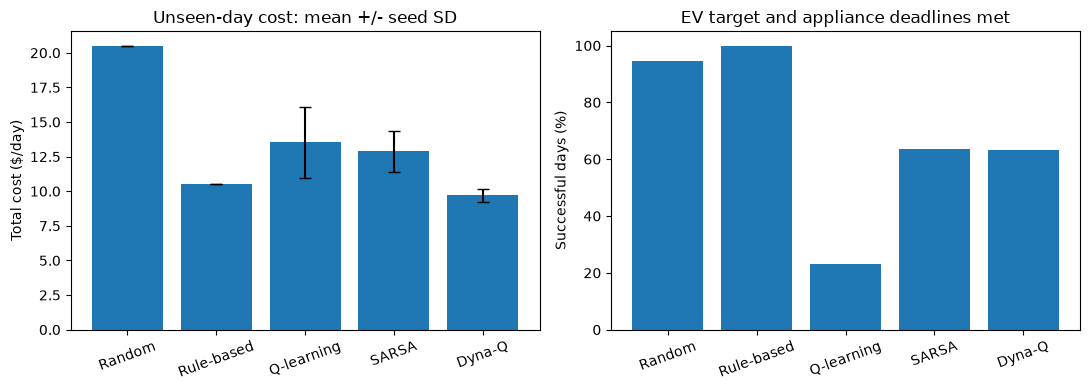

In [16]:
per_seed = test_results.groupby(["Agent","Seed"])["total_cost"].mean()
summary = per_seed.groupby("Agent").agg(["mean","std"]).fillna(0)
summary.columns = ["Mean total cost ($)","Seed SD ($)"]
components = test_results.groupby("Agent")[["bill","penalty","success","ev_shortfall","missed_jobs"]].mean()
components["success"] *= 100
components.columns = ["Mean bill ($)","Mean penalties ($)","Success (%)","EV shortfall (kWh)","Missed jobs"]
summary = summary.join(components).loc[["Random","Rule-based",*TRAINERS]]
display(summary.round(3))
fig, axes = plt.subplots(1,2,figsize=(11,4))
axes[0].bar(summary.index,summary["Mean total cost ($)"],yerr=summary["Seed SD ($)"],capsize=4)
axes[0].set(ylabel="Total cost ($/day)",title="Unseen-day cost: mean +/- seed SD")
axes[1].bar(summary.index,summary["Success (%)"])
axes[1].set(ylabel="Successful days (%)",ylim=(0,105),title="EV target and appliance deadlines met")
for ax in axes:
    ax.tick_params(axis="x",rotation=20)
plt.tight_layout()
plt.show()

# Performance under different weather

In [17]:
weather_costs = test_results.pivot_table(index="Agent",columns="weather",values="total_cost",aggfunc="mean")
display(weather_costs.reindex(summary.index).round(3))
rule_cost = summary.loc["Rule-based","Mean total cost ($)"]
for name in TRAINERS:
    saved = rule_cost-summary.loc[name,"Mean total cost ($)"]
    success = summary.loc[name,"Success (%)"]
    print(f"{name}: savings vs rule = ${saved:.3f}/day; successful days = {success:.1f}%.")

weather,cloudy,rainy,sunny
Agent,,,
Random,21.273,21.970,19.917
Rule-based,10.948,12.167,9.993
Q-learning,11.903,19.385,13.380
SARSA,14.534,16.143,11.558
Dyna-Q,10.019,14.346,8.766


Q-learning: savings vs rule = $-3.048/day; successful days = 23.1%.
SARSA: savings vs rule = $-2.406/day; successful days = 63.7%.
Dyna-Q: savings vs rule = $0.798/day; successful days = 63.3%.


# Inspect one learned schedule

Use Dyna-Q's first training seed and the first test day, chosen in advance.
The table shows commands, SOCs, costs and penalties hour by hour. The action
decoder identifies battery / EV / appliance decisions. This is one example;
the 300-day results above are the performance evidence.

In [18]:
env = EnergyEnv()
obs, _ = env.reset(seed=TEST_OFFSET)
pi = policies["Dyna-Q"][0]
schedule = []
while True:
    action = int(pi[discretise(obs)])
    obs, reward, done, truncated, info = env.step(action)
    b, e, a = decode_action(action)
    schedule.append({"Hour":info["hour"],"Battery":["charge","idle","discharge"][b],
                     "EV charge":e,"Start appliance":a,"Battery SOC":obs[2],"EV SOC":obs[3],
                     "Bill ($)":info["cost"],"Penalty ($)":info["penalty"]})
    if done or truncated:
        break
display(pd.DataFrame(schedule).round(3))

,Hour,Battery,EV charge,Start appliance,Battery SOC,EV SOC,Bill ($),Penalty ($)
0,7,idle,1,0,0.500,0.400,-0.003,0.0
1,8,idle,1,1,0.500,0.400,-0.027,0.0
2,9,idle,1,0,0.500,0.400,-0.045,0.0
3,10,idle,1,0,0.500,0.400,-0.125,0.0
4,11,charge,1,0,0.975,0.400,0.037,0.0
5,12,idle,0,1,0.975,0.400,-0.067,0.0
6,13,idle,0,1,0.975,0.400,-0.053,0.0
7,14,idle,0,0,0.975,0.400,-0.150,0.0
8,15,charge,1,0,1.000,0.400,-0.075,0.0
9,16,idle,0,1,1.000,0.400,-0.053,0.0
